1. Data Integrity Validation
   - Image and annotation matching
   - Missing files
   - Duplicate references
   - Image readability

In [2]:
import os
import json
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

DATASET_PATH = "/kaggle/input/datasets/maram05ai/clevr-cogent-v1/CLEVR_CoGenT_v1.0"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Dataset contents:", os.listdir(DATASET_PATH))

Dataset exists: True
Dataset contents: ['COPYRIGHT.txt', 'LICENSE.txt', 'README.txt', 'images', 'questions', 'scenes']


In [ ]:
import os
import json

splits = ["trainA", "valA", "valB"]

for split in splits:

    print(f"\n{'='*45}")
    print(f"Checking {split}")
    print(f"{'='*45}")

    image_dir = os.path.join(
        DATASET_PATH, "images", split
    )

    annotation_file = os.path.join(
        DATASET_PATH, "scenes",
        f"CLEVR_{split}_scenes.json"
    )

    with open(annotation_file, "r") as f:
        data = json.load(f)

    scenes = data["scenes"]

    image_files = {
        file for file in os.listdir(image_dir)
        if file.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    annotated_files = {
        scene["image_filename"] for scene in scenes
    }

    print("Number of annotations:", len(scenes))
    print("Number of images:", len(image_files))
    print("Unique annotated images:", len(annotated_files))

    print("Images without annotations:",
          len(image_files - annotated_files))

    print("Annotations without images:",
          len(annotated_files - image_files))

    print("Duplicate image references:",
          len(scenes) - len(annotated_files))

### Data Integrity Validation — Results

The image-to-annotation consistency check was performed
on trainA, valA, and valB.

Results:
- trainA: 70,000 images and 70,000 annotations.
- valA: 15,000 images and 15,000 annotations.
- valB: 15,000 images and 15,000 annotations.
- No missing images.
- No missing annotations.
- No duplicate image references.

Conclusion:
All three splits passed the image-to-annotation
consistency check.

In [ ]:
import json
import os
from collections import Counter

splits = ["trainA", "valA", "valB"]

VALID_SHAPES = {"cube", "sphere", "cylinder"}

VALID_COLORS = {
    "gray", "red", "blue", "green",
    "brown", "purple", "cyan", "yellow"
}

for split in splits:

    annotation_file = os.path.join(
        DATASET_PATH,
        "scenes",
        f"CLEVR_{split}_scenes.json"
    )

    with open(annotation_file, "r") as f:
        scenes = json.load(f)["scenes"]

    shapes = Counter()
    colors = Counter()

    invalid_shapes = []
    invalid_colors = []
    missing_attributes = []

    total_objects = 0

    for scene in scenes:
        for obj in scene["objects"]:

            total_objects += 1

            shape = obj.get("shape")
            color = obj.get("color")

            if shape not in VALID_SHAPES:
                invalid_shapes.append(shape)

            if color not in VALID_COLORS:
                invalid_colors.append(color)

            if shape is None or color is None:
                missing_attributes.append(obj)

            shapes[shape] += 1
            colors[color] += 1

    print(f"\n{'='*45}")
    print(f"Annotation Validation: {split}")
    print(f"{'='*45}")

    print("Total objects:", total_objects)
    print("Shape distribution:", dict(shapes))
    print("Color distribution:", dict(colors))

    print("Invalid shapes:", len(invalid_shapes))
    print("Invalid colors:", len(invalid_colors))
    print("Missing attributes:", len(missing_attributes))

## Shape-Color Combination Validation

In [ ]:
import os
import json
import pandas as pd

splits = ["trainA", "valA", "valB"]

combination_tables = {}
combination_sets = {}

for split in splits:

    annotation_file = os.path.join(
        DATASET_PATH,
        "scenes",
        f"CLEVR_{split}_scenes.json"
    )

    with open(annotation_file, "r") as f:
        scenes = json.load(f)["scenes"]

    combinations = []

    for scene in scenes:
        for obj in scene["objects"]:
            combinations.append({
                "shape": obj["shape"],
                "color": obj["color"]
            })

    df = pd.DataFrame(combinations)

    table = pd.crosstab(
        df["shape"],
        df["color"]
    )

    combination_tables[split] = table
    combination_sets[split] = set(
        zip(df["shape"], df["color"])
    )

    print(f"\n{'='*50}")
    print(f"Shape-Color Combinations: {split}")
    print(f"{'='*50}")

    print(table)
    print("\nNumber of observed combinations:",
          len(combination_sets[split]))

# Compare Condition B against Condition A
seen_combinations = combination_sets["trainA"]
b_combinations = combination_sets["valB"]

unseen_combinations = b_combinations - seen_combinations

print("\n" + "="*50)
print("UNSEEN COMBINATIONS IN VALB")
print("="*50)

for shape, color in sorted(unseen_combinations):
    count = combination_tables["valB"].loc[shape, color]
    print(f"{shape:10s} + {color:10s}: {count:,}")

print("\nTotal unseen combinations:",
      len(unseen_combinations))

### Shape-Color Combination Validation

The observed shape-color combinations were analyzed
across trainA, valA, and valB.

Key findings:
- trainA contains 16 observed combinations.
- valA contains the same 16 combinations as trainA.
- valB contains 16 combinations, including 8 combinations
  absent from trainA.

The unseen combinations consist of:
- Four cube-color combinations:
  red, green, purple, and cyan.
- Four cylinder-color combinations:
  gray, blue, brown, and yellow.

All eight unseen combinations are present in valB,
with 64,830 objects in total.

The remaining 32,363 objects in valB are spheres,
whose shape-color combinations were already observed
during training.

Conclusion:
Only the eight specified cube and cylinder combinations
will be considered unseen during evaluation.
The entire valB split will not be treated as unseen data.

## 4. Image Integrity Validation

This section verifies that image files are readable and
that their dimensions and formats are consistent across
the selected dataset splits.

In [ ]:
import os
from PIL import Image
from collections import Counter
from tqdm.notebook import tqdm

splits = ["trainA", "valA", "valB"]

image_validation_results = {}

for split in splits:

    image_dir = os.path.join(
        DATASET_PATH, "images", split
    )

    image_files = [
        f for f in os.listdir(image_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    corrupted_images = []
    image_dimensions = Counter()
    image_formats = Counter()

    for filename in tqdm(image_files, desc=f"Checking {split}"):

        image_path = os.path.join(image_dir, filename)

        try:
            with Image.open(image_path) as img:
                img.verify()

            # Reopen to inspect image properties
            with Image.open(image_path) as img:
                image_dimensions[img.size] += 1
                image_formats[img.format] += 1

        except Exception as e:
            corrupted_images.append({
                "filename": filename,
                "error": str(e)
            })

    image_validation_results[split] = {
        "total_images": len(image_files),
        "corrupted_images": len(corrupted_images),
        "dimensions": image_dimensions,
        "formats": image_formats
    }

    print(f"\n{'='*45}")
    print(f"Image Integrity: {split}")
    print(f"{'='*45}")

    print("Total images:", len(image_files))
    print("Corrupted images:", len(corrupted_images))
    print("Image dimensions:", dict(image_dimensions))
    print("Image formats:", dict(image_formats))

## Object Extraction Strategy

The dataset provides object-level scene annotations, including object attributes and projected pixel coordinates. However, the pixel coordinates represent object centers rather than bounding boxes.

Therefore, an object extraction strategy must be established and visually validated before generating the final object-level dataset.

The extraction method should aim to:
- Capture the complete target object.
- Minimize background and neighboring-object interference.
- Preserve the object's visual attributes, especially shape and color.
- Maintain consistent extraction criteria across all dataset splits.

In [ ]:
import os
import json

# Load trainA scene annotations
train_scenes_path = os.path.join(
    DATASET_PATH,
    "scenes",
    "CLEVR_trainA_scenes.json"
)

with open(train_scenes_path, "r") as f:
    train_scenes = json.load(f)

# Inspect one object
sample_scene = train_scenes["scenes"][0]
sample_object = sample_scene["objects"][0]

print("Available object attributes:")
for key, value in sample_object.items():
    print(f"{key}: {value}")

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Select one scene
sample_scene = train_scenes["scenes"][0]

# Load corresponding image
image_filename = sample_scene["image_filename"]
image_path = os.path.join(DATASET_PATH, "images", "trainA", image_filename)

image = Image.open(image_path)

# Display image and object centers
plt.figure(figsize=(12, 8))
plt.imshow(image)

for i, obj in enumerate(sample_scene["objects"]):
    x, y, depth = obj["pixel_coords"]

    plt.scatter(x, y, s=100, edgecolors="black")
    plt.text(
        x + 5, y - 5,
        f'{i}: {obj["shape"]}, {obj["color"]}',
        color="white",
        fontsize=9,
        bbox=dict(facecolor="black", alpha=0.6)
    )

plt.title("Object Centers in a trainA Scene")
plt.axis("off")
plt.show()

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import os

random.seed(42)

sample_scenes = random.sample(train_scenes["scenes"], 6)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for ax, scene in zip(axes.flat, sample_scenes):

    image_path = os.path.join(
        DATASET_PATH,
        "images",
        "trainA",
        scene["image_filename"]
    )

    image = Image.open(image_path)
    ax.imshow(image)

    for i, obj in enumerate(scene["objects"]):
        x, y, depth = obj["pixel_coords"]

        ax.scatter(x, y, s=70, edgecolors="black")
        ax.text(
            x + 4, y - 4,
            f'{obj["shape"]}, {obj["color"]}',
            color="white",
            fontsize=7,
            bbox=dict(facecolor="black", alpha=0.6)
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Use the previously inspected scene
scene = train_scenes["scenes"][0]

image_path = os.path.join(
    DATASET_PATH,
    "images",
    "trainA",
    scene["image_filename"]
)

image = Image.open(image_path)

fig, axes = plt.subplots(
    len(scene["objects"]), 3,
    figsize=(12, 4 * len(scene["objects"]))
)

for i, obj in enumerate(scene["objects"]):
    x, y, depth = obj["pixel_coords"]

    axes[i, 0].imshow(image)
    axes[i, 0].scatter(x, y, color="red", s=70)
    axes[i, 0].set_title(
        f'{obj["shape"]} - {obj["color"]} (Original)'
    )
    axes[i, 0].axis("off")

    for j, crop_size in enumerate([96, 128], start=1):
        half = crop_size // 2

        crop = image.crop((
            int(x - half),
            int(y - half),
            int(x + half),
            int(y + half)
        ))

        axes[i, j].imshow(crop)
        axes[i, j].set_title(f"{crop_size} × {crop_size} Crop")
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image
import os

random.seed(42)

sample_scenes = random.sample(train_scenes["scenes"], 10)
crop_sizes = [96, 112, 128]

for scene_idx, scene in enumerate(sample_scenes):

    image_path = os.path.join(
        DATASET_PATH, "images", "trainA", scene["image_filename"]
    )
    image = Image.open(image_path)

    fig, axes = plt.subplots(
        len(scene["objects"]), 4,
        figsize=(14, 3.5 * len(scene["objects"]))
    )

    for i, obj in enumerate(scene["objects"]):
        x, y, depth = obj["pixel_coords"]

        axes[i, 0].imshow(image)
        axes[i, 0].scatter(x, y, color="red", s=60)
        axes[i, 0].set_title(
            f'{obj["shape"]} - {obj["color"]}'
        )
        axes[i, 0].axis("off")

        for j, size in enumerate(crop_sizes, start=1):
            half = size // 2

            crop = image.crop((
                int(x - half), int(y - half),
                int(x + half), int(y + half)
            ))

            axes[i, j].imshow(crop)
            axes[i, j].set_title(f"{size} × {size}")
            axes[i, j].axis("off")

    plt.suptitle(f"Scene {scene_idx + 1}")
    plt.tight_layout()
    plt.show()

### Crop Boundary Validation

Before generating object crops, image-boundary handling must be validated.

A fixed-size crop centered on an object may extend beyond the original image boundaries, producing inconsistent crop dimensions.

The selected crop size is provisionally set to 112 × 112 pixels.

In [ ]:
image_width, image_height = 480, 320
crop_size = 112
half = crop_size // 2

boundary_cases = []

for scene in train_scenes["scenes"]:
    for obj in scene["objects"]:
        x, y, _ = obj["pixel_coords"]

        x1 = int(x - half)
        y1 = int(y - half)
        x2 = x1 + crop_size
        y2 = y1 + crop_size

        if (
            x1 < 0 or y1 < 0 or
            x2 > image_width or y2 > image_height
        ):
            boundary_cases.append({
                "image": scene["image_filename"],
                "shape": obj["shape"],
                "color": obj["color"],
                "center": (x, y),
                "crop_bounds": (x1, y1, x2, y2)
            })

print("Total objects checked:", sum(
    len(scene["objects"]) for scene in train_scenes["scenes"]
))
print("Objects near image boundaries:", len(boundary_cases))
print("Percentage:", round(
    len(boundary_cases) /
    sum(len(scene["objects"]) for scene in train_scenes["scenes"]) * 100,
    2
), "%")

print("\nFirst 5 boundary cases:")
for item in boundary_cases[:5]:
    print(item)

In [ ]:
# Analyze crop boundary violations

boundary_counts = {
    "left": 0,
    "right": 0,
    "top": 0,
    "bottom": 0
}

for item in boundary_cases:
    x1, y1, x2, y2 = item["crop_bounds"]

    if x1 < 0:
        boundary_counts["left"] += 1
    if x2 > image_width:
        boundary_counts["right"] += 1
    if y1 < 0:
        boundary_counts["top"] += 1
    if y2 > image_height:
        boundary_counts["bottom"] += 1

print("Boundary violation distribution:")
for boundary, count in boundary_counts.items():
    print(f"{boundary}: {count}")

print("\nTotal boundary cases:", len(boundary_cases))

In [ ]:
from PIL import ImageOps

# Pad without resizing
padded_crop = ImageOps.expand(
    original_crop,
    border=(
        max(0, -x1),  # left
        max(0, -y1),  # top
        max(0, x2 - image.width),  # right
        max(0, y2 - image.height)  # bottom
    ),
    fill=(127, 127, 127)
)

print("Original crop:", original_crop.size)
print("Padded crop:", padded_crop.size)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_crop)
axes[0].set_title("Original Crop")

axes[1].imshow(padded_crop)
axes[1].set_title("Padded Crop")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

crop_size = 112
half = crop_size // 2

test_cases = {
    "Right": next(
        item for item in boundary_cases
        if item["crop_bounds"][2] > image_width
    ),
    "Left": next(
        item for item in boundary_cases
        if item["crop_bounds"][0] < 0
    ),
    "Bottom": next(
        item for item in boundary_cases
        if item["crop_bounds"][3] > image_height
    )
}

fig, axes = plt.subplots(1, 3, figsize=(13, 5))

for ax, (case_name, item) in zip(axes, test_cases.items()):

    image_path = os.path.join(
        DATASET_PATH, "images", "trainA", item["image"]
    )

    image = Image.open(image_path).convert("RGB")

    x, y = item["center"]

    x1 = int(x - half)
    y1 = int(y - half)
    x2 = x1 + crop_size
    y2 = y1 + crop_size

    left = max(0, x1)
    top = max(0, y1)
    right = min(image.width, x2)
    bottom = min(image.height, y2)

    visible_crop = image.crop((left, top, right, bottom))

    padded_crop = Image.new(
        "RGB",
        (crop_size, crop_size),
        (127, 127, 127)
    )

    padded_crop.paste(
        visible_crop,
        (left - x1, top - y1)
    )

    print(
        f"{case_name}: "
        f"Visible={visible_crop.size}, "
        f"Final={padded_crop.size}"
    )

    assert padded_crop.size == (112, 112)

    ax.imshow(padded_crop)
    ax.set_title(case_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import os

CROP_SIZE = 112
PADDING_COLOR = (127, 127, 127)

def extract_object_crop(image_path, pixel_coords):
    """
    Extract a fixed-size object crop centered at pixel_coords.

    Returns:
        crop: RGB image of size 112x112
    """

    image = Image.open(image_path).convert("RGB")

    x, y = pixel_coords[:2]

    half = CROP_SIZE // 2

    x1 = int(x - half)
    y1 = int(y - half)
    x2 = x1 + CROP_SIZE
    y2 = y1 + CROP_SIZE

    # Intersection with the original image
    left = max(0, x1)
    top = max(0, y1)
    right = min(image.width, x2)
    bottom = min(image.height, y2)

    visible_crop = image.crop((left, top, right, bottom))

    # Fixed-size canvas
    crop = Image.new(
        "RGB",
        (CROP_SIZE, CROP_SIZE),
        PADDING_COLOR
    )

    crop.paste(
        visible_crop,
        (left - x1, top - y1)
    )

    return crop

In [ ]:
sample_scene = train_scenes["scenes"][0]
sample_object = sample_scene["objects"][0]

sample_image_path = os.path.join(
    DATASET_PATH,
    "images",
    "trainA",
    sample_scene["image_filename"]
)

sample_crop = extract_object_crop(
    sample_image_path,
    sample_object["pixel_coords"]
)

print("Image:", sample_scene["image_filename"])
print("Shape:", sample_object["shape"])
print("Color:", sample_object["color"])
print("Crop dimensions:", sample_crop.size)

display(sample_crop)

In [ ]:
import random

random.seed(42)

sample_scenes = random.sample(
    train_scenes["scenes"],
    10
)

test_results = []

for scene in sample_scenes:
    for obj in scene["objects"]:

        image_path = os.path.join(
            DATASET_PATH,
            "images",
            "trainA",
            scene["image_filename"]
        )

        crop = extract_object_crop(
            image_path,
            obj["pixel_coords"]
        )

        test_results.append({
            "image": scene["image_filename"],
            "shape": obj["shape"],
            "color": obj["color"],
            "crop_size": crop.size,
            "valid": crop.size == (112, 112)
        })

print("Total extracted crops:", len(test_results))
print("Valid crops:", sum(r["valid"] for r in test_results))
print("Invalid crops:", sum(not r["valid"] for r in test_results))

In [ ]:
import os
import json
import random
import matplotlib.pyplot as plt
from PIL import Image

DATASET_PATH = (
    "/kaggle/input/datasets/maram05ai/"
    "clevr-cogent-v1/CLEVR_CoGenT_v1.0"
)

train_scenes_path = os.path.join(
    DATASET_PATH,
    "scenes",
    "CLEVR_trainA_scenes.json"
)

with open(train_scenes_path, "r") as f:
    train_scenes = json.load(f)

print("Dataset path exists:", os.path.exists(DATASET_PATH))
print("Number of trainA scenes:", len(train_scenes["scenes"]))
print("First scene:", train_scenes["scenes"][0]["image_filename"])

In [ ]:
import matplotlib.pyplot as plt
import random

random.seed(42)

visual_samples = random.sample(test_results, 12)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))

for ax, result in zip(axes.flat, visual_samples):

    image_path = os.path.join(
        DATASET_PATH,
        "images",
        "trainA",
        result["image"]
    )

    scene = next(
        s for s in sample_scenes
        if s["image_filename"] == result["image"]
    )

    obj = next(
        o for o in scene["objects"]
        if o["shape"] == result["shape"]
        and o["color"] == result["color"]
    )

    crop = extract_object_crop(
        image_path,
        obj["pixel_coords"]
    )

    ax.imshow(crop)
    ax.set_title(f'{result["shape"]} - {result["color"]}')
    ax.axis("off")

plt.tight_layout()
plt.show()

In [1]:
import os
import json
import random
import matplotlib.pyplot as plt
from PIL import Image

DATASET_PATH = (
    "/kaggle/input/datasets/maram05ai/"
    "clevr-cogent-v1/CLEVR_CoGenT_v1.0"
)

train_scenes_path = os.path.join(
    DATASET_PATH,
    "scenes",
    "CLEVR_trainA_scenes.json"
)

with open(train_scenes_path, "r") as f:
    train_scenes = json.load(f)

print("Dataset path exists:", os.path.exists(DATASET_PATH))
print("Number of trainA scenes:", len(train_scenes["scenes"]))
print("First scene:", train_scenes["scenes"][0]["image_filename"])

Dataset path exists: True
Number of trainA scenes: 70000
First scene: CLEVR_trainA_000000.png


In [3]:
CROP_SIZE = 112
PADDING_COLOR = (127, 127, 127)

def extract_object_crop(image_path, pixel_coords):
    image = Image.open(image_path).convert("RGB")

    x, y = pixel_coords[:2]
    half = CROP_SIZE // 2

    x1 = int(x - half)
    y1 = int(y - half)
    x2 = x1 + CROP_SIZE
    y2 = y1 + CROP_SIZE

    left = max(0, x1)
    top = max(0, y1)
    right = min(image.width, x2)
    bottom = min(image.height, y2)

    visible_crop = image.crop((left, top, right, bottom))

    crop = Image.new(
        "RGB",
        (CROP_SIZE, CROP_SIZE),
        PADDING_COLOR
    )

    crop.paste(
        visible_crop,
        (left - x1, top - y1)
    )

    return crop

Shape: sphere
Color: yellow
Crop size: (112, 112)


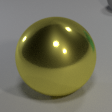

In [4]:
sample_scene = train_scenes["scenes"][0]
sample_object = sample_scene["objects"][0]

sample_image_path = os.path.join(
    DATASET_PATH,
    "images",
    "trainA",
    sample_scene["image_filename"]
)

sample_crop = extract_object_crop(
    sample_image_path,
    sample_object["pixel_coords"]
)

print("Shape:", sample_object["shape"])
print("Color:", sample_object["color"])
print("Crop size:", sample_crop.size)

display(sample_crop)

In [5]:
import shutil

usage = shutil.disk_usage("/kaggle/working")

print(f"Total: {usage.total / (1024**3):.2f} GB")
print(f"Used: {usage.used / (1024**3):.2f} GB")
print(f"Free: {usage.free / (1024**3):.2f} GB")

Total: 19.52 GB
Used: 0.00 GB
Free: 19.50 GB


In [6]:
import io
import random

random.seed(42)

scenes_sample = random.sample(
    train_scenes["scenes"], 200
)

sample_sizes = []

for scene in scenes_sample:
    image_path = os.path.join(
        DATASET_PATH, "images", "trainA",
        scene["image_filename"]
    )

    for obj in scene["objects"]:
        crop = extract_object_crop(
            image_path, obj["pixel_coords"]
        )

        buffer = io.BytesIO()
        crop.save(buffer, format="JPEG", quality=95)
        sample_sizes.append(buffer.tell())

        if len(sample_sizes) >= 1000:
            break

    if len(sample_sizes) >= 1000:
        break

avg_size_kb = sum(sample_sizes) / len(sample_sizes) / 1024
estimated_gb = avg_size_kb * 455024 / (1024**2)

print("Sample crops:", len(sample_sizes))
print(f"Average JPEG size: {avg_size_kb:.2f} KB")
print(f"Estimated trainA size: {estimated_gb:.2f} GB")

Sample crops: 1000
Average JPEG size: 3.14 KB
Estimated trainA size: 1.36 GB


In [6]:
import os

OUTPUT_PATH = "/kaggle/working/clevr_cogent_processed"

folders = [
    "trainA/images",
    "valA/images",
    "valB_unseen/images"
]

for folder in folders:
    os.makedirs(
        os.path.join(OUTPUT_PATH, folder),
        exist_ok=True
    )

print("Dataset directory structure created successfully.")

for root, dirs, files in os.walk(OUTPUT_PATH):
    level = root.replace(OUTPUT_PATH, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

Dataset directory structure created successfully.
clevr_cogent_processed/
    trainA/
        images/
    valB_unseen/
        images/
    valA/
        images/


In [8]:
import os
import json
import csv
from pathlib import Path
from PIL import Image

DATASET_PATH = (
    "/kaggle/input/datasets/maram05ai/"
    "clevr-cogent-v1/CLEVR_CoGenT_v1.0"
)

OUTPUT_PATH = "/kaggle/working/clevr_cogent_processed"

train_scenes_path = os.path.join(
    DATASET_PATH, "scenes", "CLEVR_trainA_scenes.json"
)

with open(train_scenes_path, "r") as f:
    train_scenes = json.load(f)

CROP_SIZE = 112
PADDING_COLOR = (127, 127, 127)

def extract_object_crop(image_path, pixel_coords):
    image = Image.open(image_path).convert("RGB")

    x, y = pixel_coords[:2]
    half = CROP_SIZE // 2

    x1 = int(x - half)
    y1 = int(y - half)
    x2 = x1 + CROP_SIZE
    y2 = y1 + CROP_SIZE

    left = max(0, x1)
    top = max(0, y1)
    right = min(image.width, x2)
    bottom = min(image.height, y2)

    visible_crop = image.crop((left, top, right, bottom))

    crop = Image.new(
        "RGB", (CROP_SIZE, CROP_SIZE), PADDING_COLOR
    )
    crop.paste(visible_crop, (left - x1, top - y1))

    return crop

print("Train scenes loaded:", len(train_scenes["scenes"]))
print("Output directory exists:", os.path.exists(OUTPUT_PATH))

Train scenes loaded: 70000
Output directory exists: True


In [9]:
import csv
from pathlib import Path

TEST_OUTPUT = Path(OUTPUT_PATH) / "trainA"
TEST_IMAGES = TEST_OUTPUT / "images"
TEST_METADATA = TEST_OUTPUT / "metadata_test.csv"

rows = []

for scene in train_scenes["scenes"][:100]:
    image_filename = scene["image_filename"]
    image_path = os.path.join(
        DATASET_PATH, "images", "trainA", image_filename
    )

    for obj_index, obj in enumerate(scene["objects"]):
        crop = extract_object_crop(
            image_path, obj["pixel_coords"]
        )

        crop_filename = (
            f"{Path(image_filename).stem}_obj{obj_index}.jpg"
        )

        crop.save(
            TEST_IMAGES / crop_filename,
            format="JPEG",
            quality=95
        )

        rows.append({
            "crop_filename": crop_filename,
            "source_image": image_filename,
            "object_index": obj_index,
            "shape": obj["shape"],
            "color": obj["color"],
            "material": obj["material"],
            "size": obj["size"],
            "pixel_x": obj["pixel_coords"][0],
            "pixel_y": obj["pixel_coords"][1]
        })

with open(TEST_METADATA, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0].keys())
    writer.writeheader()
    writer.writerows(rows)

print("Scenes processed:", 100)
print("Objects extracted:", len(rows))
print("Metadata rows:", len(rows))
print("First crop:", rows[0]["crop_filename"])

Scenes processed: 100
Objects extracted: 630
Metadata rows: 630
First crop: CLEVR_trainA_000000_obj0.jpg


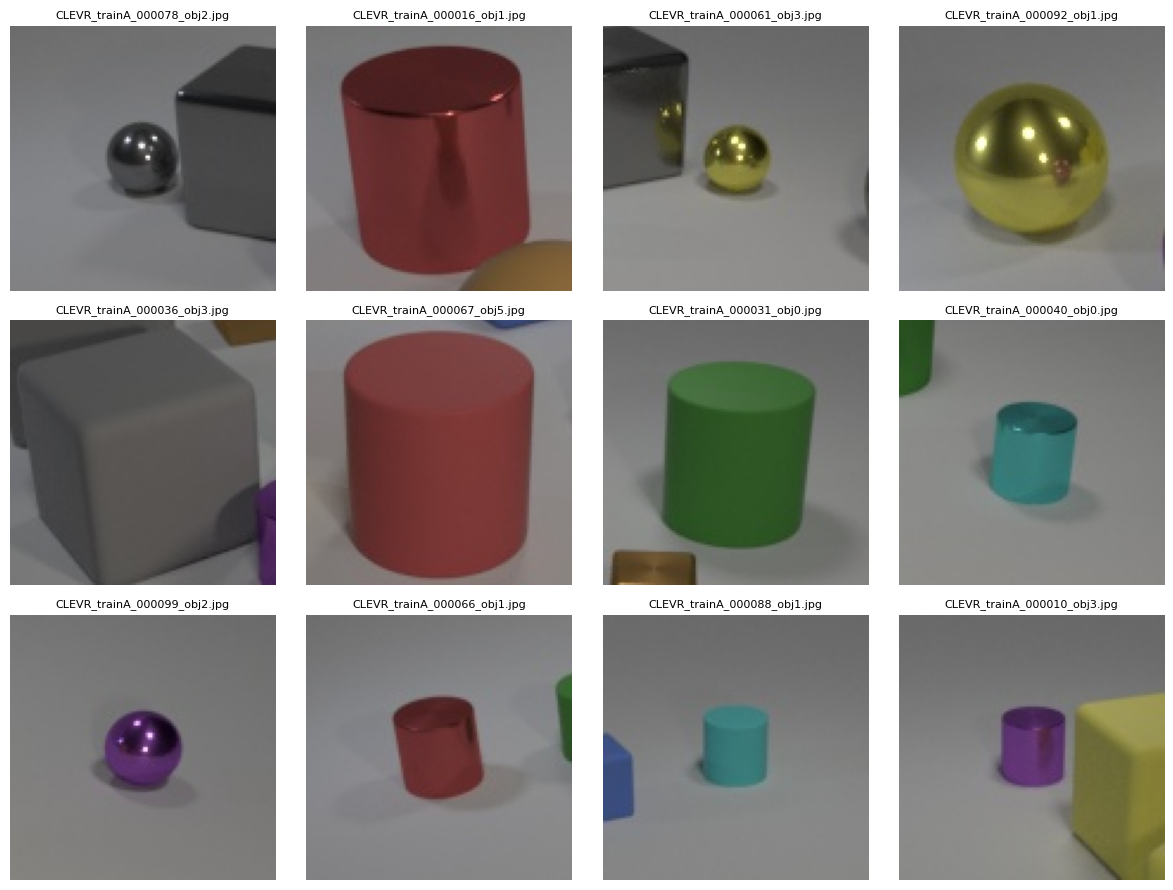

Total saved crops: 630
All sampled crops have size 112x112.


In [10]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

TEST_IMAGES = Path(OUTPUT_PATH) / "trainA" / "images"

sample_files = random.sample(
    list(TEST_IMAGES.glob("*.jpg")),
    12
)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, image_file in zip(axes.flat, sample_files):
    img = Image.open(image_file)

    ax.imshow(img)
    ax.set_title(image_file.name, fontsize=8)
    ax.axis("off")

    assert img.size == (112, 112), (
        f"Unexpected image size: {image_file.name}"
    )

plt.tight_layout()
plt.show()

print("Total saved crops:", len(list(TEST_IMAGES.glob("*.jpg"))))
print("All sampled crops have size 112x112.")

In [11]:
from pathlib import Path

TRAIN_OUTPUT = Path(OUTPUT_PATH) / "trainA"
METADATA_PARTS = TRAIN_OUTPUT / "metadata_parts"

METADATA_PARTS.mkdir(parents=True, exist_ok=True)

# Remove the temporary test crops and metadata
for file in (TRAIN_OUTPUT / "images").glob("*.jpg"):
    file.unlink()

test_metadata = TRAIN_OUTPUT / "metadata_test.csv"

if test_metadata.exists():
    test_metadata.unlink()

print("Final extraction folders prepared.")
print("Images directory:", TRAIN_OUTPUT / "images")
print("Metadata parts directory:", METADATA_PARTS)
print("Temporary test files removed.")

Final extraction folders prepared.
Images directory: /kaggle/working/clevr_cogent_processed/trainA/images
Metadata parts directory: /kaggle/working/clevr_cogent_processed/trainA/metadata_parts
Temporary test files removed.


In [12]:
import csv
from pathlib import Path
from tqdm.auto import tqdm

BATCH_SIZE = 5000
START_INDEX = 0
END_INDEX = min(START_INDEX + BATCH_SIZE, len(train_scenes["scenes"]))

TRAIN_IMAGES = Path(OUTPUT_PATH) / "trainA" / "images"
METADATA_PARTS = Path(OUTPUT_PATH) / "trainA" / "metadata_parts"

metadata_rows = []

for scene_index in tqdm(range(START_INDEX, END_INDEX)):
    scene = train_scenes["scenes"][scene_index]
    image_filename = scene["image_filename"]

    image_path = os.path.join(
        DATASET_PATH, "images", "trainA", image_filename
    )

    for obj_index, obj in enumerate(scene["objects"]):
        crop = extract_object_crop(
            image_path, obj["pixel_coords"]
        )

        crop_filename = (
            f"{Path(image_filename).stem}_obj{obj_index}.jpg"
        )

        crop.save(
            TRAIN_IMAGES / crop_filename,
            format="JPEG",
            quality=95
        )

        metadata_rows.append({
            "crop_filename": crop_filename,
            "source_image": image_filename,
            "scene_index": scene_index,
            "object_index": obj_index,
            "shape": obj["shape"],
            "color": obj["color"],
            "material": obj["material"],
            "size": obj["size"],
            "pixel_x": obj["pixel_coords"][0],
            "pixel_y": obj["pixel_coords"][1]
        })

metadata_path = METADATA_PARTS / "metadata_00000_04999.csv"

with open(metadata_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=metadata_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(metadata_rows)

print("Scenes processed:", END_INDEX - START_INDEX)
print("Objects extracted:", len(metadata_rows))
print("Metadata saved:", metadata_path)
print("Last scene index:", END_INDEX - 1)

  0%|          | 0/5000 [00:00<?, ?it/s]

Scenes processed: 5000
Objects extracted: 32384
Metadata saved: /kaggle/working/clevr_cogent_processed/trainA/metadata_parts/metadata_00000_04999.csv
Last scene index: 4999


In [13]:
BATCH_SIZE = 5000
START_INDEX = 5000
END_INDEX = min(START_INDEX + BATCH_SIZE, len(train_scenes["scenes"]))

metadata_rows = []

for scene_index in tqdm(range(START_INDEX, END_INDEX)):
    scene = train_scenes["scenes"][scene_index]
    image_filename = scene["image_filename"]

    image_path = os.path.join(
        DATASET_PATH, "images", "trainA", image_filename
    )

    for obj_index, obj in enumerate(scene["objects"]):
        crop = extract_object_crop(
            image_path, obj["pixel_coords"]
        )

        crop_filename = (
            f"{Path(image_filename).stem}_obj{obj_index}.jpg"
        )

        crop.save(
            TRAIN_IMAGES / crop_filename,
            format="JPEG",
            quality=95
        )

        metadata_rows.append({
            "crop_filename": crop_filename,
            "source_image": image_filename,
            "scene_index": scene_index,
            "object_index": obj_index,
            "shape": obj["shape"],
            "color": obj["color"],
            "material": obj["material"],
            "size": obj["size"],
            "pixel_x": obj["pixel_coords"][0],
            "pixel_y": obj["pixel_coords"][1]
        })

metadata_path = METADATA_PARTS / "metadata_05000_09999.csv"

with open(metadata_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=metadata_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(metadata_rows)

print("Scenes processed:", END_INDEX - START_INDEX)
print("Objects extracted:", len(metadata_rows))
print("Metadata saved:", metadata_path)
print("Last scene index:", END_INDEX - 1)

  0%|          | 0/5000 [00:00<?, ?it/s]

Scenes processed: 5000
Objects extracted: 32539
Metadata saved: /kaggle/working/clevr_cogent_processed/trainA/metadata_parts/metadata_05000_09999.csv
Last scene index: 9999


In [14]:
BATCH_SIZE = 5000
START_INDEX = 10000
END_INDEX = min(
    START_INDEX + BATCH_SIZE,
    len(train_scenes["scenes"])
)

metadata_rows = []

for scene_index in tqdm(range(START_INDEX, END_INDEX)):
    scene = train_scenes["scenes"][scene_index]
    image_filename = scene["image_filename"]

    image_path = os.path.join(
        DATASET_PATH, "images", "trainA", image_filename
    )

    for obj_index, obj in enumerate(scene["objects"]):
        crop = extract_object_crop(
            image_path, obj["pixel_coords"]
        )

        crop_filename = (
            f"{Path(image_filename).stem}_obj{obj_index}.jpg"
        )

        crop.save(
            TRAIN_IMAGES / crop_filename,
            format="JPEG",
            quality=95
        )

        metadata_rows.append({
            "crop_filename": crop_filename,
            "source_image": image_filename,
            "scene_index": scene_index,
            "object_index": obj_index,
            "shape": obj["shape"],
            "color": obj["color"],
            "material": obj["material"],
            "size": obj["size"],
            "pixel_x": obj["pixel_coords"][0],
            "pixel_y": obj["pixel_coords"][1]
        })

metadata_path = (
    METADATA_PARTS / "metadata_10000_14999.csv"
)

with open(metadata_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=metadata_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(metadata_rows)

print("Scenes processed:", END_INDEX - START_INDEX)
print("Objects extracted:", len(metadata_rows))
print("Metadata saved:", metadata_path)
print("Last scene index:", END_INDEX - 1)

  0%|          | 0/5000 [00:00<?, ?it/s]

Scenes processed: 5000
Objects extracted: 32550
Metadata saved: /kaggle/working/clevr_cogent_processed/trainA/metadata_parts/metadata_10000_14999.csv
Last scene index: 14999


In [15]:
BATCH_SIZE = 5000
START_INDEX = 15000
END_INDEX = min(
    START_INDEX + BATCH_SIZE,
    len(train_scenes["scenes"])
)

metadata_rows = []

for scene_index in tqdm(range(START_INDEX, END_INDEX)):
    scene = train_scenes["scenes"][scene_index]
    image_filename = scene["image_filename"]

    image_path = os.path.join(
        DATASET_PATH, "images", "trainA", image_filename
    )

    for obj_index, obj in enumerate(scene["objects"]):
        crop = extract_object_crop(
            image_path, obj["pixel_coords"]
        )

        crop_filename = (
            f"{Path(image_filename).stem}_obj{obj_index}.jpg"
        )

        crop.save(
            TRAIN_IMAGES / crop_filename,
            format="JPEG",
            quality=95
        )

        metadata_rows.append({
            "crop_filename": crop_filename,
            "source_image": image_filename,
            "scene_index": scene_index,
            "object_index": obj_index,
            "shape": obj["shape"],
            "color": obj["color"],
            "material": obj["material"],
            "size": obj["size"],
            "pixel_x": obj["pixel_coords"][0],
            "pixel_y": obj["pixel_coords"][1]
        })

metadata_path = (
    METADATA_PARTS / "metadata_15000_19999.csv"
)

with open(metadata_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=metadata_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(metadata_rows)

print("Scenes processed:", END_INDEX - START_INDEX)
print("Objects extracted:", len(metadata_rows))
print("Metadata saved:", metadata_path)
print("Last scene index:", END_INDEX - 1)

  0%|          | 0/5000 [00:00<?, ?it/s]

Scenes processed: 5000
Objects extracted: 32517
Metadata saved: /kaggle/working/clevr_cogent_processed/trainA/metadata_parts/metadata_15000_19999.csv
Last scene index: 19999


In [16]:
BATCH_SIZE = 5000
START_INDEX = 20000
END_INDEX = min(
    START_INDEX + BATCH_SIZE,
    len(train_scenes["scenes"])
)

metadata_rows = []

for scene_index in tqdm(range(START_INDEX, END_INDEX)):
    scene = train_scenes["scenes"][scene_index]
    image_filename = scene["image_filename"]

    image_path = os.path.join(
        DATASET_PATH, "images", "trainA", image_filename
    )

    for obj_index, obj in enumerate(scene["objects"]):
        crop = extract_object_crop(
            image_path, obj["pixel_coords"]
        )

        crop_filename = (
            f"{Path(image_filename).stem}_obj{obj_index}.jpg"
        )

        crop.save(
            TRAIN_IMAGES / crop_filename,
            format="JPEG",
            quality=95
        )

        metadata_rows.append({
            "crop_filename": crop_filename,
            "source_image": image_filename,
            "scene_index": scene_index,
            "object_index": obj_index,
            "shape": obj["shape"],
            "color": obj["color"],
            "material": obj["material"],
            "size": obj["size"],
            "pixel_x": obj["pixel_coords"][0],
            "pixel_y": obj["pixel_coords"][1]
        })

metadata_path = (
    METADATA_PARTS / "metadata_20000_24999.csv"
)

with open(metadata_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=metadata_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(metadata_rows)

print("Scenes processed:", END_INDEX - START_INDEX)
print("Objects extracted:", len(metadata_rows))
print("Metadata saved:", metadata_path)
print("Last scene index:", END_INDEX - 1)

  0%|          | 0/5000 [00:00<?, ?it/s]

Scenes processed: 5000
Objects extracted: 32474
Metadata saved: /kaggle/working/clevr_cogent_processed/trainA/metadata_parts/metadata_20000_24999.csv
Last scene index: 24999


In [17]:
BATCH_SIZE = 5000
START_INDEX = 25000
END_INDEX = min(
    START_INDEX + BATCH_SIZE,
    len(train_scenes["scenes"])
)

metadata_rows = []

for scene_index in tqdm(range(START_INDEX, END_INDEX)):
    scene = train_scenes["scenes"][scene_index]
    image_filename = scene["image_filename"]

    image_path = os.path.join(
        DATASET_PATH, "images", "trainA", image_filename
    )

    for obj_index, obj in enumerate(scene["objects"]):
        crop = extract_object_crop(
            image_path, obj["pixel_coords"]
        )

        crop_filename = (
            f"{Path(image_filename).stem}_obj{obj_index}.jpg"
        )

        crop.save(
            TRAIN_IMAGES / crop_filename,
            format="JPEG",
            quality=95
        )

        metadata_rows.append({
            "crop_filename": crop_filename,
            "source_image": image_filename,
            "scene_index": scene_index,
            "object_index": obj_index,
            "shape": obj["shape"],
            "color": obj["color"],
            "material": obj["material"],
            "size": obj["size"],
            "pixel_x": obj["pixel_coords"][0],
            "pixel_y": obj["pixel_coords"][1]
        })

metadata_path = (
    METADATA_PARTS / "metadata_25000_29999.csv"
)

with open(metadata_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=metadata_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(metadata_rows)

print("Scenes processed:", END_INDEX - START_INDEX)
print("Objects extracted:", len(metadata_rows))
print("Metadata saved:", metadata_path)
print("Last scene index:", END_INDEX - 1)

  0%|          | 0/5000 [00:00<?, ?it/s]

Scenes processed: 5000
Objects extracted: 32435
Metadata saved: /kaggle/working/clevr_cogent_processed/trainA/metadata_parts/metadata_25000_29999.csv
Last scene index: 29999
